# Project 3: Thought Cascade

## ECE4424/CS4824: Machine Learning
**Instructor:** Prof. Ming Jin

## Submission requirements

1. Complete the six functions marked `TODO` in this notebook.
2. Write directly in the **Required analysis** cells for Q2, Q3 and Q6. Double-click
   a Markdown cell to edit it, then press Shift+Enter to render your answer.
3. Run the experiment cells so the tables, plots and repair trace are visible.
4. Submit **one PDF of your completed notebook**, including your implementations,
   written answers and results. Use the print-export cell at the end. Keep the
   `.ipynb` and JSON log as backups; they are not additional required submissions.

This individual assignment is worth 100 points and 10% of the course grade:
Q1 (15), Q2 (10), Q3 (10), Q4 (10), Q5 (10) and Q6 (45).
See the [course schedule](https://jinming.tech/learn-ml-by-building/schedule.html)
for the deadline. All questions and grading instructions are in this notebook.

## Introduction

An LLM can write plausible code and still miss an edge case. You will build a
loop that proposes a repair, runs tests, and tries again using the results.
You will measure when that feedback helps.

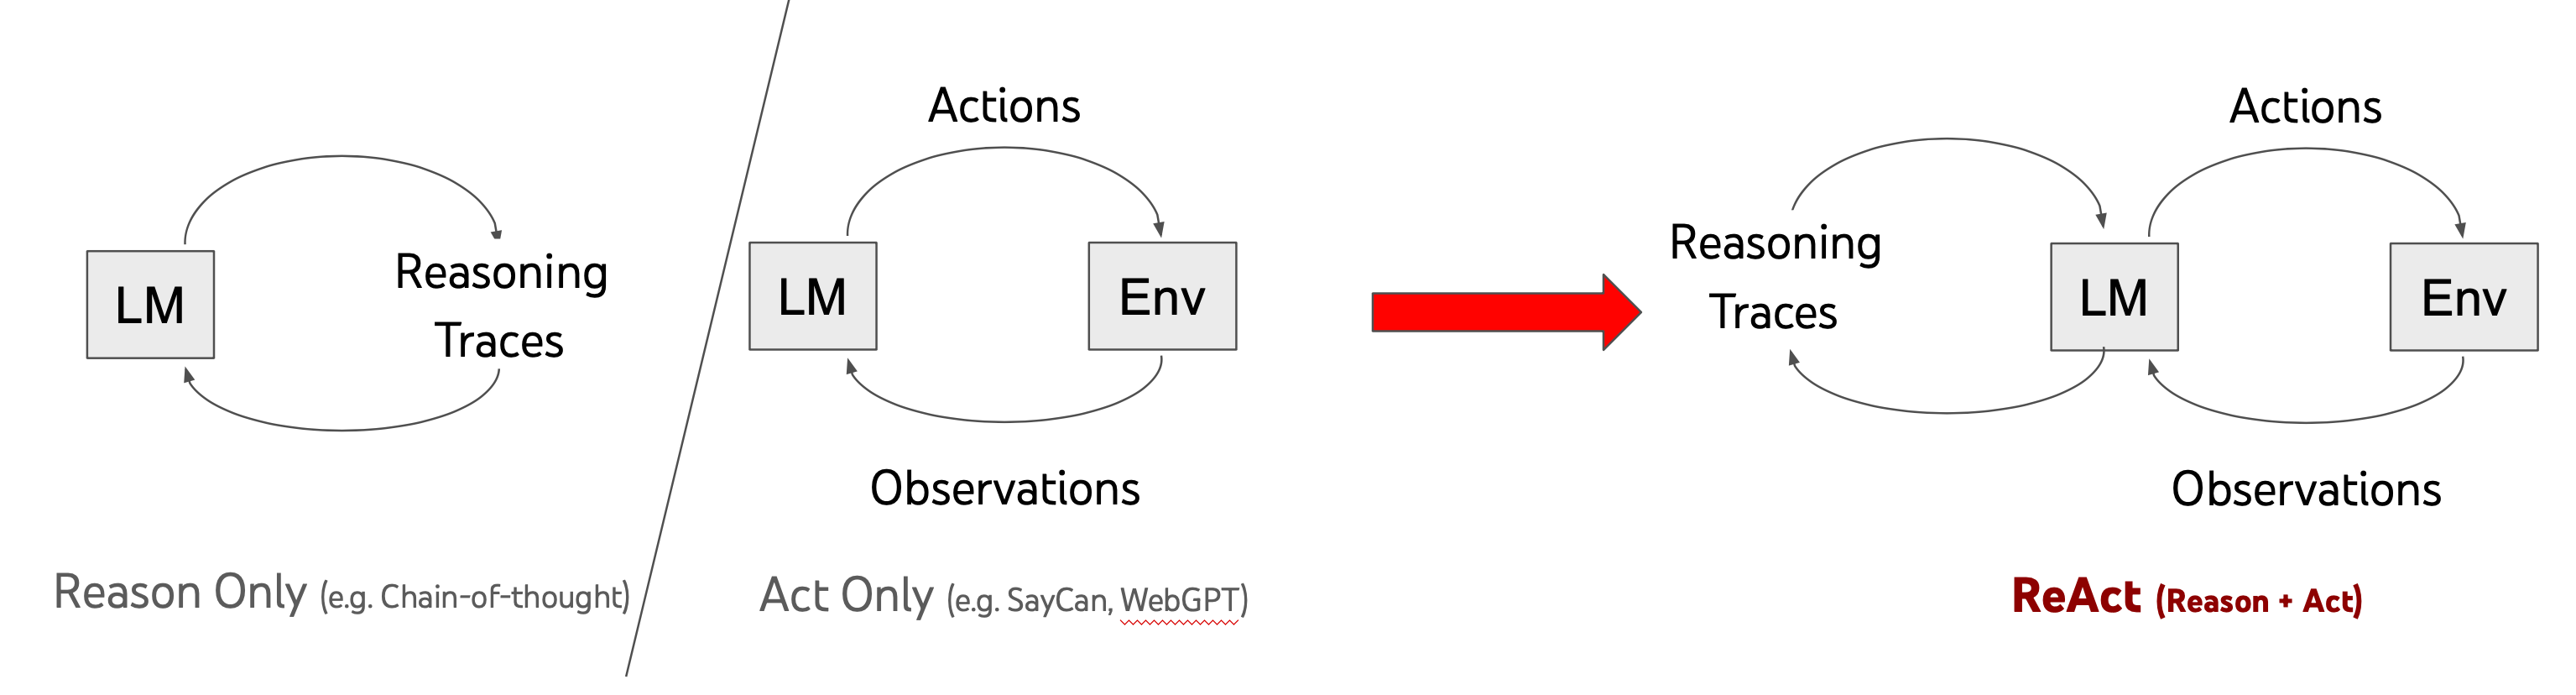

The original ReAct diagram, from [Yao et al.](https://react-lm.github.io/).
In our version, an action is a code patch and the environment is a Python test runner.

## Getting started

Open [Google Colab](https://colab.research.google.com/), choose **File > Upload
notebook**, and select this file. Select **Runtime > Change runtime type > T4 GPU**,
then run setup and work through Q1-Q6 in order. You should be comfortable with
Python functions, loops, lists, dictionaries and reading exceptions. Lecture 17
introduces prompts, tools and observations; the worked example below reviews
the controller used here.

The notebook includes its helpers, data and illustrations. It uses Qwen3-1.7B
in 4-bit NF4; no token or paid API is needed.


In [ ]:
# @title Setup — run this cell first
import base64, hashlib, io, json, os, subprocess, sys, zipfile
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
# Bundled helpers and public test fixtures; no solutions or recorded responses.
# Rerunning setup replaces extracted helpers. Complete exercises in the notebook.
SUPPORT_FILES = '...'
if IN_COLAB:
    root = Path('/content/thought-cascade')
else:
    root = Path.cwd()
    if root.name != '.thought_cascade':
        root = root / '.thought_cascade'
root.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(io.BytesIO(base64.b64decode(SUPPORT_FILES))) as archive:
    archive.extractall(root)
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
# Detect accidental file corruption; this is not a tamper-proof authenticity check.
for name, digest in json.loads(Path('source_manifest.json').read_text()).items():
    assert hashlib.sha256(Path(name).read_bytes()).hexdigest() == digest, name
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
else:
    print('Local use: install requirements.txt; 4-bit generation supports CUDA or Apple Silicon (MPS).')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')
print('Working directory:', root)


Allow about 10–15 minutes for setup and the experiments; runtime varies.
This is computer runtime, not the time needed to complete the assignment.
Plan separate work sessions for implementation, experiments and written analysis.
The required work uses seeds 11, 22 and 33 and at most 57 model calls:
six in Q1, three in Q3 and 48 in Q6.

Free Colab GPUs are subject to availability. If none is available, complete the
deterministic and scripted checks, skip live generation, and ask staff for
recorded results. Label those results as recorded. Do not purchase compute.

Complete your functions in notebook cells. Rerunning setup replaces the extracted
support files; edits made inside `.thought_cascade` will be lost.

## The repair loop

Each round has three steps: generate a short debugging plan, generate a code
patch, and run the development tests. The controller keeps the best candidate
and decides whether another round is needed. Model loading, execution and logging
are supplied.

Each round uses two model calls. Qwen’s internal thinking mode stays off.
The written plan is a proposal to inspect; it may be wrong or ignored by the patch.

A plan is text proposed by the model. An action is the Python module it produces.
An observation is the test runner’s result. The controller is ordinary Python:
it decides what information goes into the next prompt. You are not training a model.

In [ ]:
import copy
import json
import random
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Code, Markdown, display
from utils.cascade import (
    QwenClient, SEEDS, BINARY_TASK, MINIMAL, observe, execute, extract_code,
    validate_action, context_for, single_shot, load_quixbugs, save_log, trajectory_row,
)
from utils.checks import check_q1, check_components, check_loop

## Q1. Tests and metrics (15 points)

The supplied binary search should return the **leftmost** matching index in a
sorted integer list, or −1 when absent. Binary search repeatedly halves a sorted list. In a half-open interval
`[left, right)`, `right` is excluded; updating a bound must preserve that convention.
For a leftmost match, finding a matching value does not rule out earlier matches.
The supplied code breaks both requirements:

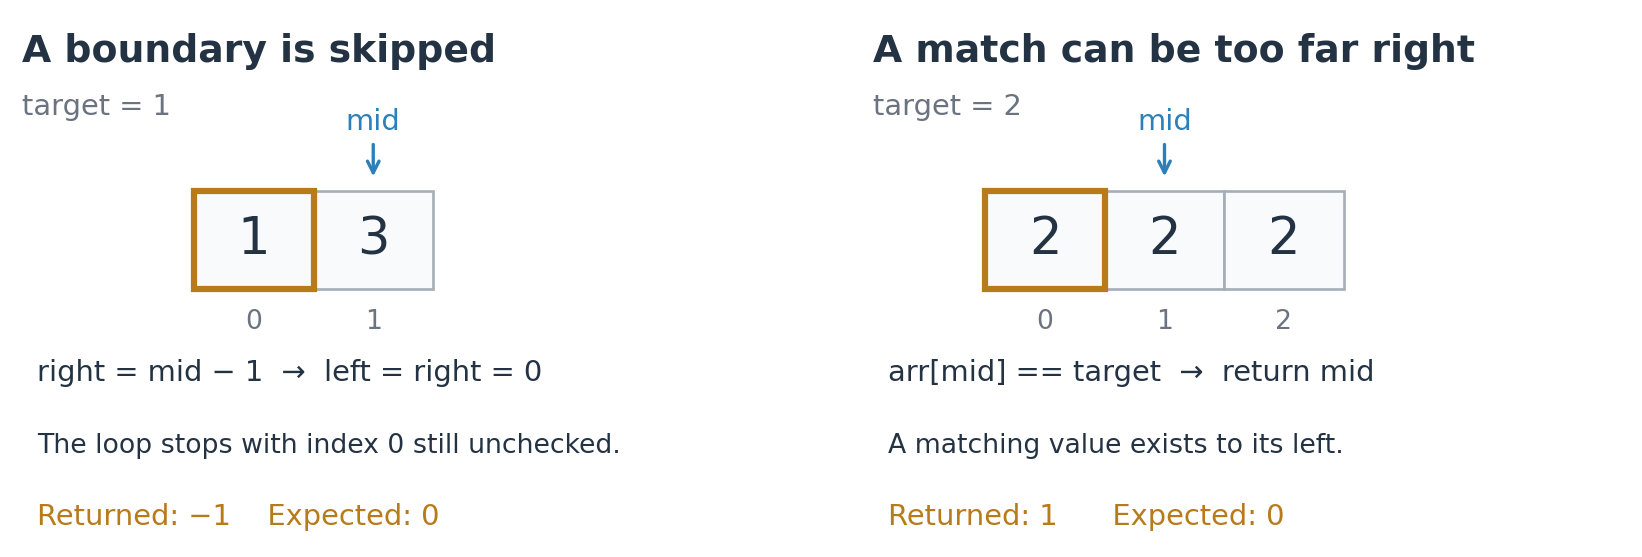

Trace these cases through the code below. A few passing tests can hide both bugs.

A test is `(args, expected)`, where `args` lists the positional arguments.
For example, `([[2, 2, 3], 2], 0)` expects index 0. Implement:

- `leftmost_index_or_minus_one` (3 points): an independent linear-scan oracle.
- `build_strict_tests` (7): at least 10 distinct explicit cases covering empty and singleton
  lists, first/last index, absent below/between/above, negative values and duplicates.
  Add exactly `n_random` cases using a local `random.Random(seed)`: sorted arrays
  of length 0–20, values −10…10 and targets −12…12. Label cases with your oracle.
- `measure_single_shot_success` (5): summarize saved attempts without making new
  model calls. Return `attempts`, `success_rate` (fraction passing all tests),
  `avg_pass_rate` (mean fraction of tests passed), and `compilation_rate`.
  Raise `ValueError` for empty input. Include every attempt, including syntax
  errors, timeouts, rejected code and runtime errors. Leave the records unchanged.

In [ ]:
# Read the actual debugging task before implementing its evaluator.
display(Markdown(BINARY_TASK['spec']))
display(Code(BINARY_TASK['code'], language='python'))
display(pd.DataFrame(MINIMAL, columns=['positional arguments', 'expected result']))

binary_search(arr, target): arr is a nondecreasing list of integers. Return the LEFTMOST index of target, or -1 when absent. Empty lists and duplicates are valid. Do not mutate the inputs.

def binary_search(arr, target):
 left, right = 0, len(arr)
 while left < right:
 mid = (left + right) // 2
 if arr[mid] == target:
 return mid
 elif arr[mid] < target:
 left = mid + 1
 else:
 right = mid - 1
 return -1

Positional arguments,Expected result
"[[1, 3, 5, 7], 1]",0
"[[1, 3, 5, 7], 7]",3
"[[1, 3, 5, 7], 2]",-1
"[[], 1]",-1


Each attempt has an `observation` dictionary. Read `all_passed` (bool),
`pass_rate` (float), and `compilation` (`'success'`, `'error'`, or `'not_attempted'`).

For example, two compiling attempts with pass fractions 1.0 and 0.5 have success
rate 0.5, average pass rate 0.75 and compilation rate 1.0.

If one patch passes 91 of 100 held-out cases, its case pass rate is 91%, but it
is not a successful repair. Those 100 cases evaluate one patch; they are not
100 independent model attempts. Compilation only checks Python syntax.

In [ ]:
def leftmost_index_or_minus_one(arr, target):
    # TODO Q1: return an int; do not reuse the buggy search.
    raise NotImplementedError("Complete the Q1 oracle.")


def build_strict_tests(seed=123, n_random=100):
    # TODO Q1: list of (args, expected), e.g. [([[2, 2], 2], 0), ...].
    raise NotImplementedError("Complete the Q1 strict test builder.")


def measure_single_shot_success(records):
    # TODO Q1: read each record['observation']; preserve the original records.
    raise NotImplementedError("Complete the Q1 metrics aggregator.")

In [ ]:
check_q1(leftmost_index_or_minus_one, build_strict_tests, measure_single_shot_success)
STRICT = build_strict_tests(seed=123, n_random=100)
coverage = pd.DataFrame([
    {'suite': name, **observe(BINARY_TASK, BINARY_TASK['code'], tests)}
    for name, tests in [('MINIMAL', MINIMAL), ('STRICT', STRICT)]
])
display(coverage[['suite', 'passed', 'total', 'pass_rate']])
ax = coverage.plot.bar(x='suite', y='pass_rate', ylim=(0, 1.12), rot=0,
                       legend=False, figsize=(6, 3.5), color='#2c7fb8',
                       title='Same buggy code, different test coverage')
ax.bar_label(ax.containers[0], labels=[f"{r.passed}/{r.total} cases" for r in coverage.itertuples()], padding=5)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_yticks([0, .25, .5, .75, 1])
ax.set_ylabel('Fraction of tests passed')
ax.set_xlabel('Test suite')
plt.tight_layout()
plt.show()
strict_observation = coverage.loc[coverage['suite'] == 'STRICT'].iloc[0]
display(pd.DataFrame(strict_observation['failures']))

MINIMAL should pass all four cases; STRICT must expose failures. Your exact
STRICT count depends on the cases you wrote.

The runner uses a fresh subprocess with a 3-second timeout and basic source
checks, but is not a security sandbox. Inspect generated code and use a disposable
Colab runtime without mounting Drive or adding secrets. Helpers and allowed
standard-library imports are retained; `flatten` uses an adapter for its generator output.

### Generate and rescore

Model loading and quantization are supplied, not assessed. Keep these settings: a pinned Qwen3-1.7B revision, its native chat
template, `enable_thinking=False`, temperature 0.7, top-p 0.8 and top-k 20.
NF4 uses double quantization and FP16 compute. Plans get 128 output tokens;
patches get 512. Inputs plus outputs are capped at 4096 tokens. Keep truncated
attempts in the results.

The next cells make six calls: three binary-search attempts and one each for
`gcd`, `flatten` and `lcs_length`. Rescore the same binary-search outputs on STRICT;
those cases never enter the prompt. Changing the tests changes the measurement,
not the generated code. An unchanged buggy patch is still a failed repair.

In [ ]:
client = QwenClient(quantized=True)
display(client.metadata)

In [ ]:
# Three fixed seeds; score the SAME three outputs under both evaluators.
baseline = [single_shot(client, BINARY_TASK, MINIMAL, seed) for seed in SEEDS]
baseline_strict = [dict(r, observation=observe(BINARY_TASK, r['code'], STRICT)) for r in baseline]
baseline_table = pd.DataFrame([
    {'suite': 'MINIMAL', **measure_single_shot_success(baseline)},
    {'suite': 'STRICT', **measure_single_shot_success(baseline_strict)},
])
display(baseline_table)
display(pd.DataFrame([
    {'Seed': r['seed'], 'Code changed': r['code_changed'],
     'MINIMAL': f"{r['observation']['passed']}/{r['observation']['total']}",
     'STRICT': f"{s['observation']['passed']}/{s['observation']['total']}"}
    for r, s in zip(baseline, baseline_strict)
]))
save_log('results/student_run.json', client, coverage=coverage.to_dict('records'), test_suites={'minimal': MINIMAL, 'strict': STRICT},
         baseline=baseline, baseline_strict=baseline_strict)

In [ ]:
# A small, vetted QuixBugs sample, one attempt per task. Missing fixtures are errors.
# These are public benchmark tests, not held-out generalization evidence.
# lcs_length means longest common SUBSTRING (contiguous), not subsequence.
quix_records = []
for name in ('gcd', 'flatten', 'lcs_length'):
    task, tests = load_quixbugs(name)
    record = single_shot(client, task, tests, seed=11)
    quix_records.append(dict(record, task=name))
    save_log('results/student_run.json', client, quixbugs=quix_records)
quix_table = pd.DataFrame([
    {'task': r['task'], 'compilation': r['observation']['compilation'],
     'status': r['observation']['status'], 'pass_rate': r['observation']['pass_rate'],
     'runtime_errors': r['observation']['runtime_errors'],
     'wrong_answers': r['observation']['wrong_answers']}
    for r in quix_records
])
display(quix_table.rename(columns={'compilation': 'Compiles', 'pass_rate': 'Cases passed',
    'runtime_errors': 'Exceptions', 'wrong_answers': 'Wrong answers'}).round(3))
save_log('results/student_run.json', client, baseline=baseline, baseline_strict=baseline_strict,
         quixbugs=quix_records)

## Q2. Analyze the results (10 points)

Write 200–350 words covering:

1. The original code's MINIMAL and STRICT counts, with one failing input and
   an explanation of the bug (3 points).
2. The same three generated outputs under both suites. Distinguish changed
   measurement from changed model behavior (3).
3. Syntax, execution and logical failures in your saved records (2).
   Inspect exception counts and failures; `tested` only means the suite ran. If a category
   did not occur, say so; label any synthetic examples.
4. Why one attempt on each of three QuixBugs tasks cannot establish consistent
   performance, and why public tests do not establish generalization (2).

### Required analysis - Q2

Your answer:

## Q3. Compare two prompts (10 points)

Prompt A contains the specification, two examples and original code. B adds:
“Before writing, check loop bounds, duplicates, and empty input against the
specification.” Both request the complete Python module.

Reuse A's saved outputs. Generate B with the same seeds, settings and output
budget, then evaluate both on STRICT. Keep STRICT out of the prompts and do not
regenerate A selectively.

Report the table and one paired code comparison, including whether either patch
changed the starter (5 points). Explain the result
and the uncertainty from three seeds (5), including a ceiling effect if both
prompts pass every test. Aim for 100-200 words, excluding the table and code.

In [ ]:
prompt_b = [single_shot(client, BINARY_TASK, STRICT, seed, variant='B') for seed in SEEDS]
prompt_table = pd.DataFrame([
    {'prompt': 'A', **measure_single_shot_success(baseline_strict),
     'changed_attempts': sum(r['code_changed'] for r in baseline)},
    {'prompt': 'B', **measure_single_shot_success(prompt_b),
     'changed_attempts': sum(r['code_changed'] for r in prompt_b)},
])
display(prompt_table)
display(Markdown('**Prompt A — seed 11**'))
display(Code(baseline[0]['code'], language='python'))
display(Markdown('**Prompt B — seed 11**'))
display(Code(prompt_b[0]['code'], language='python'))
save_log('results/student_run.json', client, prompt_b=prompt_b)

### Required analysis - Q3

Your answer:

## Helper functions

| Function | Returns |
|---|---|
| `client.generate(prompt, seed, max_new_tokens)` | Generation record; makes one model call |
| `extract_code(text)` | Complete Python source |
| `validate_action(action)` | `(is_valid, error_message)` |
| `observe(task, code, tests)` | Observation dictionary |
| `context_for(task, code, observation)` | Prompt context string |

A generation record contains `text`, `prompt`, `seed`, `input_tokens`,
`output_tokens`, `max_new_tokens`, `truncated`, and `seconds`.

An observation contains `status`, `compilation`, `passed`, `total`, `pass_rate`,
`all_passed`, and `failures`. All cases are scored; up to three failures are kept,
with arguments, expected/actual results and errors. The supplied runner also counts `runtime_errors`, `wrong_answers` and
`input_mutations` across all cases, even when only three failures are displayed.
Module-level errors use an `error` string; they are distinct from per-case exceptions. Only `client.generate` makes a model call.

### Current code and best code

This worked example uses invented scores, not model results. The next prompt uses
**current code**; final evaluation uses **best code**. Both conditions follow this rule.

| After testing | Current candidate | Development score | Best candidate |
|---|---|---|---|
| Start | Original | 2/4 | Original |
| Round 1 | Patch A | 3/4 | Patch A |
| Round 2 | Patch B | 1/4 | Patch A |

If another round were allowed, it would revise Patch B. Only the feedback
condition would also receive Patch B's test results. At the end, Patch A is
selected. Ties retain the earlier best candidate. Held-out tests play no part
in these decisions.


## Q4. Generate a plan (10 points)

Implement `generate_thought(client, context, seed)`. Include the supplied context
unchanged: specification, examples, current code and any development feedback.
Ask for a diagnosis and one proposed change in at most three sentences, without
code. Make one `client.generate` call with the given seed and
`max_new_tokens=128`. Return the full generation record.

Points: complete context (4), focused instruction (3), correct seed, token limit
and return value (3).

Keep this function task-independent. Do not append a known solution, decoder
mapping or test answers. Staff inspect these prompts as well as the scripted checks.

In [ ]:
def generate_thought(client, context, seed):
    # TODO Q4
    raise NotImplementedError("Complete the Q4 plan generator.")

## Q5. Generate an action (10 points)

Implement `generate_action(client, context, thought, seed)`, where `thought` is
the plan text. Include the complete context and plan. Request the complete corrected
Python module in one code block with no prose. Make one call with the given seed
and `max_new_tokens=512`, then use `extract_code`.

Return `(action, generation_record)`, where
`action = {'tool': 'fix_code', 'params': {'code': extracted_code}}`.
Construct the dictionary in Python. `validate_action` checks its structure;
the executor checks Python syntax.

Points: context and plan (4), code extraction and action structure (4),
reproducible record (2).

In [ ]:
def generate_action(client, context, thought, seed):
    # TODO Q5
    raise NotImplementedError("Complete the Q5 action generator.")

In [ ]:
check_components(generate_thought, generate_action)
for malformed in (None, {}, {'tool': 'fix_code', 'params': None},
                  {'tool': 'fix_code', 'params': {'code': ''}}):
    assert not validate_action(malformed)[0]

## Q6. Implement the loop (45 points)

Implement `react_loop` as follows:

1. Evaluate the original code on development tests. Initialize the current and
   best candidates to that code. Return zero rounds if it already passes.
2. In zero-based round `i`, both conditions use the latest code. Include the
   latest observation only when `feedback=True` and `i > 0`:
   `context_for(task, current_code, current_observation if feedback and i > 0 else None)`.
   Neither condition sees test results in round one. Without feedback, never
   include test results, scores or failure descriptions in model prompts.
3. Call `thought_fn` and `action_fn` with seeds `seed + 2*i` and `seed + 2*i + 1`.
   Validate the action before reading its code. For invalid actions, retain the
   preceding code and record `status='invalid_action'`, `compilation='not_attempted'`,
   `passed=0`, `total=len(dev_tests)`, `pass_rate=0.0`, `all_passed=False`,
   `failures=[]`, and `error` set to the validation message.
4. Test valid actions with `observe(task, code, dev_tests)`, retaining the task's
   function name and output adapter. Each step records `thought`, `generation`,
   `action`, `action_valid`, `code`, and `observation`.
5. Update the current code and observation in both conditions, including failures.
   Update the best candidate only when its development pass rate strictly
   increases; ties keep the earlier candidate. Stop on development success or
   after `max_rounds`. Make no extra model calls.
6. Return a dictionary with `task`, `seed`, `feedback`, `steps`, `selected_code`,
   and `selected_observation`. Select using development tests only. Keep the full
   trace in `steps`, but send only the latest code and permitted observation.

Both controllers use development scores for stopping and selection. The treatment
is whether the **model** receives those results when making its second repair.

The controller earns 20 points: initialization and context (6), validation and
step records (5), selection and stopping (6), and seeds and call limits (3).
Scripted checks earn 5 points. The experiment earns 10: complete paired runs (4),
tables and costs (3), and the trajectory plot and code comparison (3). Analysis
earns 10: interpreting outcomes (3), tracing a change or failure (3), checking
paired first rounds (2), and explaining information and generalization limits (2).

In [ ]:
def react_loop(client, task, dev_tests, seed, feedback=True, max_rounds=2,
               thought_fn=generate_thought, action_fn=generate_action):
    # TODO Q6: see the six numbered requirements above.
    raise NotImplementedError("Complete the Q6 controller.")

In [ ]:
scripted_demo = check_loop(react_loop, generate_thought, generate_action)
display(pd.DataFrame([
    {'round': i + 1, 'status': s['observation']['status'],
     'passed': s['observation']['passed'], 'total': s['observation']['total']}
    for i, s in enumerate(scripted_demo['steps'])
]))

The check above uses scripted responses: a syntax error followed by a correct
patch. It tests the controller’s recovery, not the model’s accuracy.

### When does feedback help?

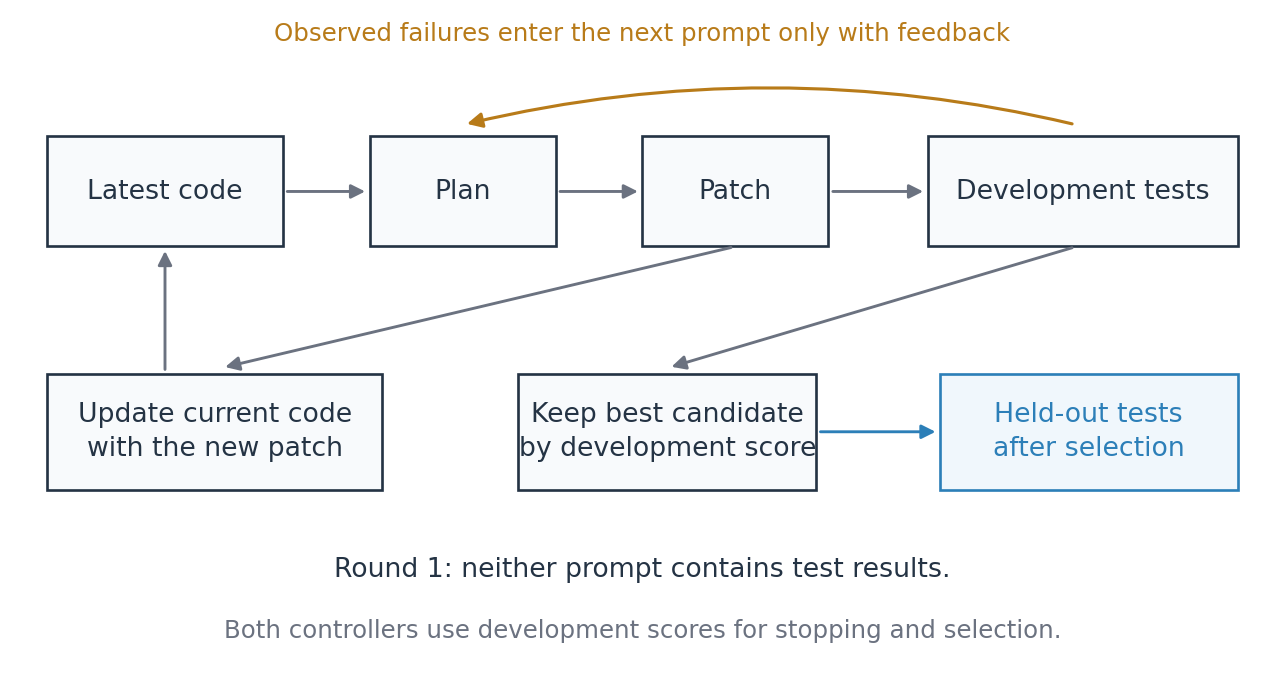

Run two tasks, three seeds (11, 22, 33) and two conditions: 12 runs, with at most
two rounds and four calls each. Both conditions revise their latest code. Only
the feedback condition sees development results in round two. Check that each
pair’s first prompt, plan and patch match before interpreting a difference.

- **Binary search:** its specification already states the required behavior.
  Use your STRICT suite. A counterexample may still fail to change the code.
- **Device-status decoding:** the specification lists the possible codes and
  labels but omits their correspondence; listing order does not define it.
  Tests supply missing information rather than merely repeating the specification.
  Codes are case-sensitive; unknown codes map to `unknown`.

Keep the supplied decoder starter (`return ['unknown' for code in codes]`) and
its development cases unchanged. Do not add the mapping or expected outputs to
initial prompts. From round two, `context_for` supplies only the permitted
observations. The mapping is visible in the helper for auditing.

Score each selected candidate on 100 disjoint cases. Keep these held-out cases
out of prompts and selection, and do not tune after viewing them. The decoder’s
new lists use the same mapping: success does not establish transfer to a new device.

Report calls, input/output tokens and generation time. Equal call limits can
have different costs. Comparing Q1 with Q6 also changes the use of a generated
plan, so it cannot isolate iteration. The next cell saves each run; rerunning
it makes new model calls.

In [ ]:
from utils.experiment_cases import make_experiment_tasks
experiment_tasks = make_experiment_tasks(STRICT)
suites = {'minimal': MINIMAL, 'strict': STRICT, 'repair_tasks': {
    task['name']: {'development': dev, 'heldout': held}
    for task, dev, held in experiment_tasks
}}
runs, trajectory_rows = [], []
for task, dev_tests, heldout in experiment_tasks:
    for seed in SEEDS:
        for feedback in (False, True):
            call_start = len(client.calls)
            run = react_loop(client, task, dev_tests, seed, feedback, max_rounds=2,
                             thought_fn=generate_thought, action_fn=generate_action)
            run['model_calls'] = copy.deepcopy(client.calls[call_start:])
            runs.append(run)
            trajectory_rows.append({'task': task['name'], **trajectory_row(run, heldout)})
            save_log('results/student_run.json', client, test_suites=suites,
                     runs=runs, trajectory_rows=trajectory_rows)
            assert len(run['model_calls']) <= 4, 'Q6 exceeded four calls; inspect the saved trace.'
            assert len(run['model_calls']) == 2 * len(run['steps']), 'Expected one plan and one patch call per round.'
            print(f"Saved {len(runs)}/12 runs: {task['name']}, seed={seed}, feedback={feedback}")

### Results

The following cells use saved results and make no model calls. Compare whole-task
successes, test pass fractions and costs.

“Code changed” compares source text after stripping outer whitespace. A change
can be cosmetic or wrong. “Selected changed” compares the selected candidate
with the starter; “Changed rounds” compares each patch with the code it received.

In [ ]:
trajectory_table = pd.DataFrame(trajectory_rows)
trajectory_table['condition'] = trajectory_table['feedback'].map(
    {False: 'Without test feedback', True: 'With test feedback'})
display(trajectory_table.assign(feedback_label=trajectory_table['feedback'].map({False: 'No', True: 'Yes'}))[
    ['task', 'seed', 'feedback_label', 'changed_steps', 'selected_changed',
     'heldout_success', 'heldout_pass_rate']
].rename(columns={'task': 'Task', 'seed': 'Seed', 'feedback_label': 'Feedback', 'rounds': 'Rounds',
                  'changed_steps': 'Changed rounds', 'selected_changed': 'Selected changed',
                  'heldout_success': 'Solved', 'heldout_pass_rate': 'Held-out'}).round(3))
summary = trajectory_table.groupby(['task', 'condition'], sort=False).agg(
    successes=('heldout_success', 'sum'), trials=('heldout_success', 'size'),
    mean_case_pass_rate=('heldout_pass_rate', 'mean'), mean_calls=('calls', 'mean'),
    mean_input_tokens=('input_tokens', 'mean'), mean_output_tokens=('output_tokens', 'mean'),
    mean_generation_seconds=('generation_seconds', 'mean'),
).reset_index()
display(summary[['task', 'condition', 'successes', 'trials', 'mean_case_pass_rate', 'mean_calls']]
        .rename(columns={'task': 'Task', 'condition': 'Condition', 'successes': 'Solved',
                         'trials': 'Trials', 'mean_case_pass_rate': 'Cases passed', 'mean_calls': 'Mean calls'}).round(3))
display(summary[['task', 'condition', 'mean_input_tokens', 'mean_output_tokens', 'mean_generation_seconds']]
        .rename(columns={'task': 'Task', 'condition': 'Condition', 'mean_input_tokens': 'Input tokens',
                         'mean_output_tokens': 'Output tokens', 'mean_generation_seconds': 'Seconds'}).round(1))
condition_order = ['Without test feedback', 'With test feedback']
plot_data = summary.pivot(index='task', columns='condition', values='mean_case_pass_rate')[condition_order]
ax = plot_data.plot.bar(ylim=(0, 1.2), rot=0, width=.8, figsize=(8, 4.5), color=['#2c7fb8', '#f0a44b'])
for condition, container in zip(condition_order, ax.containers):
    rows = summary[summary['condition'] == condition].set_index('task').loc[plot_data.index]
    labels = [f"{r.mean_case_pass_rate:.0%} cases\n{int(r.successes)}/{int(r.trials)} successes"
              for r in rows.itertuples()]
    ax.bar_label(container, labels=labels, padding=5, fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_yticks([0, .25, .5, .75, 1])
ax.set_ylabel('Mean fraction of held-out cases passed')
ax.set_xlabel('Task')
ax.set_title('Does feedback improve repairs under the same call limit?')
ax.legend(title=None, loc='upper center', bbox_to_anchor=(.5, -.15), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

In [ ]:
# Plot actual candidates, not the best-so-far envelope. No new model calls.
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), sharey=True)
for ax, (task, dev_tests, _) in zip(axes, experiment_tasks):
    for feedback, color, offset in [(False, '#2c7fb8', -.025), (True, '#b87b19', .025)]:
        for j, seed in enumerate(SEEDS):
            run = next(r for r in runs if r['task']['name'] == task['name']
                       and r['feedback'] == feedback and r['seed'] == seed)
            values = [observe(task, task['code'], dev_tests)['pass_rate']]
            values += [s['observation']['pass_rate'] for s in run['steps']]
            # Tiny horizontal offsets separate coincident traces; scores are unchanged.
            x = [i + offset + (j - 1) * .012 for i in range(len(values))]
            ax.plot(x, values, color=color, marker=['o', 's', '^'][j], markersize=4,
                    linestyle=['-', '--', ':'][j], alpha=.8,
                    label=f"{'Feedback' if feedback else 'No feedback'}, seed {seed}")
    ax.set(title=task['name'], xticks=[0, 1, 2], xticklabels=['Starter', 'Round 1', 'Round 2'],
           ylim=(-.04, 1.07), yticks=[0, .25, .5, .75, 1])
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Development cases passed')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False, fontsize=8)
fig.tight_layout(rect=[0, .17, 1, 1])
plt.show()


In [ ]:
# Check the paired first round without claiming that seeds guarantee cross-device identity.
pair_rows = []
for task, _, _ in experiment_tasks:
    for seed in SEEDS:
        pair = {r['feedback']: r for r in runs
                if r['task']['name'] == task['name'] and r['seed'] == seed}
        a, b = pair[False]['steps'], pair[True]['steps']
        if a and b:
            pair_rows.append({'task': task['name'], 'seed': seed,
                'same_first_prompt': a[0]['thought']['prompt'] == b[0]['thought']['prompt'],
                'same_first_plan': a[0]['thought']['text'] == b[0]['thought']['text'],
                'same_first_patch': a[0]['generation']['text'] == b[0]['generation']['text']})
        else:
            pair_rows.append({'task': task['name'], 'seed': seed,
                              'note': 'An initial candidate passed without a model call.'})
display(pd.DataFrame(pair_rows))

In [ ]:
# Choose examples using development outcomes only; all runs remain in the tables.
# Prefer the first complete repair, then the first improvement, then the first run.
import difflib
for task, _, _ in experiment_tasks:
    candidates = [r for r in runs if r['task']['name'] == task['name'] and r['feedback']]
    repaired = [r for r in candidates if len(r['steps']) >= 2
                and not r['steps'][0]['observation']['all_passed']
                and r['steps'][-1]['observation']['all_passed']]
    improved = [r for r in candidates if len(r['steps']) >= 2
                and r['steps'][-1]['observation']['pass_rate'] > r['steps'][0]['observation']['pass_rate']]
    trace = (repaired or improved or candidates)[0]
    display(Markdown(f"**{task['name']} - seed {trace['seed']}, with feedback**"))
    previous = task['code']
    rows = []
    for i, step in enumerate(trace['steps'], 1):
        obs = step['observation']
        rows.append({'Round': i, 'Code changed': step['code'].strip() != previous.strip(),
                     'Development': f"{obs['passed']}/{obs['total']}", 'Status': obs['status']})
        previous = step['code']
    display(pd.DataFrame(rows))
    if len(trace['steps']) >= 2:
        first, second = trace['steps'][:2]
        display(Markdown('Round-one failures supplied to the second prompt:'))
        display(pd.DataFrame(first['observation']['failures']))
        display(Markdown('Second-round plan:'))
        print(second['thought']['text'])
        patch_diff = ''.join(difflib.unified_diff(
            first['code'].splitlines(keepends=True), second['code'].splitlines(keepends=True),
            fromfile='round_1', tofile='round_2', lineterm='\n'))
        if patch_diff:
            display(Code(patch_diff, language='diff'))
        else:
            print('No code change between rounds; the same failures remain.')
    else:
        print('Stopped before a second patch; inspect the saved trace for the reason.')
    print('Selected candidate equals starter:', trace['selected_code'].strip() == task['code'].strip())


### Analyze the experiment

Write 250-400 words, excluding tables and code. Refer to the generated tables;
you do not need to copy their numbers into another table.

- Compare held-out successes out of three, case pass rates and costs for both
  tasks. Distinguish a changed patch from an improved or successful repair.
  If the selected code is the starter, say so.
- Trace one actual two-round run: the failing input, plan, code change (or lack
  of change), and whether the patch addressed the failure. Use the trajectory
  plot to describe progress or regressions. If all runs stop in round one,
  explain why they cannot show a second-round benefit.
- Check that paired first-round prompts, plans and patches match. Investigate
  mismatches before attributing a difference to feedback.
- Explain what information the decoder lacks and what the feedback supplies.
  Binary-search feedback illustrates a requirement already in the specification.
  What do three seeds, two tasks and one device mapping allow you to conclude?


### Required analysis - Q6

Your answer:

Use your saved evidence. Improvements, failures and null results can all earn
full credit; do not rerun until a desired result appears. Staff validation records
are included with the instructor package. Their scores are not grading targets.

## Save and submit as PDF

Submit one PDF containing your six implementations, three written answers,
result tables, plots and the code comparisons. Name it `LastName_FirstName_Project3.pdf`.
Keep the completed `.ipynb` and `results/student_run.json` as backups.

The next cell saves the log. To print the notebook:

1. **Save the completed notebook.** In Colab, choose **File > Download > Download
   .ipynb** after your answers and outputs are present.
2. Run the print-export cell below. In Colab, select that downloaded `.ipynb`
   when prompted; the printable HTML downloads automatically. In local Jupyter,
   save first; the HTML is written beside your notebook.
3. Open the HTML in Chrome and choose **Print > Save as PDF**. Turn off browser
   headers and footers. Check that answers, code, tables and figures are complete
   before submitting.

The export keeps all questions, graded code and results. It omits the bundled
setup and supplied execution code. It makes no model calls, so printing does
not require rerunning the experiments. You do not need a separate report.


In [ ]:
save_log('results/student_run.json', client,
         analysis_tables={'baseline': baseline_table.to_dict('records'),
                          'quixbugs': quix_table.to_dict('records'),
                          'prompt_comparison': prompt_table.to_dict('records'),
                          'repair_summary': summary.to_dict('records')})
result_path = Path('results/student_run.json').resolve()
print(f'Saved {len(client.calls)} model calls to {result_path}')
if IN_COLAB:
    from google.colab import files
    files.download(str(result_path))

In [ ]:
# Run after saving the completed notebook. This makes no model calls.
from utils.export import export_submission
export_submission()

Optional, ungraded: choose one change and a fixed extra call budget before running
it. For example, reveal the decoder mapping in both prompts or test a different
mapping. No training, larger-model comparison or agent framework is required.
Do not spend money on an extension.

References: [Qwen3](https://huggingface.co/Qwen/Qwen3-1.7B),
[4-bit loading](https://huggingface.co/docs/transformers/quantization/bitsandbytes),
[Colab limits](https://research.google.com/colaboratory/faq.html),
[ReAct](https://react-lm.github.io/), [QuixBugs](https://github.com/jkoppel/QuixBugs).